In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("student-mat.csv", sep=";")
print("Shape:", df.shape)
df.head()

Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print("Rows , Columns",df.shape)
print("Column names : \n",list(df.columns))
df.info()


Rows , Columns (395, 33)
Column names : 
 ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  

In [3]:
print("Missing values per column : \n",df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column : 
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Duplicate rows: 0


In [4]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


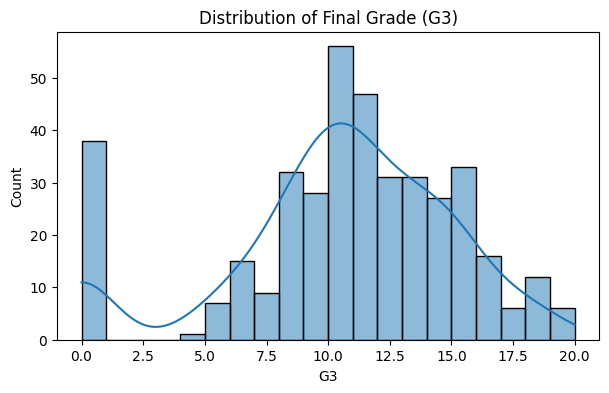

In [5]:
print(df["G3"].describe())
plt.figure(figsize=(7,4))
sns.histplot(df["G3"],bins=20,kde=True)
plt.title("Distribution of Final Grade (G3)")
plt.show()

In [6]:
df["result"]=(df["G3"]>=10).astype(int)
print(df["result"].value_counts())

result
1    265
0    130
Name: count, dtype: int64


In [8]:
nums_cols=df.select_dtypes(include="number").columns.tolist()
cat_cols=df.select_dtypes(include="object").columns.tolist()
print("Numeric : ",nums_cols)
print("Categorical : ",cat_cols)

Numeric :  ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'result']
Categorical :  ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


              age    absences          G1          G2          G3
count  395.000000  395.000000  395.000000  395.000000  395.000000
mean    16.696203    5.708861   10.908861   10.713924   10.415190
std      1.276043    8.003096    3.319195    3.761505    4.581443
min     15.000000    0.000000    3.000000    0.000000    0.000000
25%     16.000000    0.000000    8.000000    9.000000    8.000000
50%     17.000000    4.000000   11.000000   11.000000   11.000000
75%     18.000000    8.000000   13.000000   13.000000   14.000000
max     22.000000   75.000000   19.000000   19.000000   20.000000


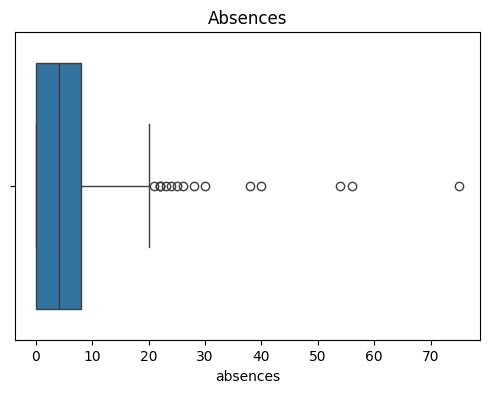

In [10]:
print(df[["age","absences","G1","G2","G3"]].describe())
plt.figure(figsize=(6,4))
sns.boxplot(x=df["absences"])
plt.title("Absences")
plt.show()

In [12]:
drop_A=["G3","result"]
drop_B=["G1","G2","G3","result"]


In [13]:
df_encoded=pd.get_dummies(df,drop_first=True)
print("Shape after encoding",df_encoded.shape)
df_encoded.head()

Shape after encoding (395, 43)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,True,False,True,False,False,False,True,True,False,False
1,17,1,1,1,2,0,5,3,3,1,...,False,False,False,True,False,False,False,True,True,False
2,15,1,1,1,2,3,4,3,2,2,...,True,False,True,False,True,False,True,True,True,False
3,15,4,2,1,3,0,3,2,2,1,...,True,False,False,True,True,True,True,True,True,True
4,16,3,3,1,2,0,4,3,2,1,...,False,False,False,True,True,False,True,True,False,False


In [14]:
print(df_encoded.dtypes.value_counts())

bool     26
int64    17
Name: count, dtype: int64


In [16]:
y=df_encoded["result"]
X_A= df_encoded.drop(columns=drop_A)
X_B=df_encoded.drop(columns=drop_B)

print("X_A shape : ",X_A.shape)
print("X_B shape : ", X_B.shape)
print("y distribution:\n",y.value_counts())

X_A shape :  (395, 41)
X_B shape :  (395, 39)
y distribution:
 result
1    265
0    130
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import train_test_split
XA_train,XA_test,y_test,y_test=train_test_split(X_A,y,test_size=0.2, random_state=42, stratify=y)
XB_train, XB_test, _, _ = train_test_split(
    X_B, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", XA_train.shape, "Test:", XA_test.shape)

Train: (316, 41) Test: (79, 41)


In [18]:
from sklearn.preprocessing import StandardScaler

scaler_B = StandardScaler()
XB_train_scaled = scaler_B.fit_transform(XB_train)
XB_test_scaled = scaler_B.transform(XB_test)

scaler_A = StandardScaler()
XA_train_scaled = scaler_A.fit_transform(XA_train)
XA_test_scaled = scaler_A.transform(XA_test)

In [19]:
import joblib
joblib.dump(scaler_B, "scaler_B.pkl")
joblib.dump(list(X_B.columns), "feature_columns_B.pkl")

['feature_columns_B.pkl']